Name

Labpartner(s)

In [1]:
#import statements go here


# Class 7.2

Today your assignment is the rest of the pandas unit and to catch up and think about your project topic, which is due by Sunday 10/13.

**W.1** Implement a function that takes as input three variables, and returns the largest of the three. Do this without using the Python max() function.

The goal of this exercise is to think about some internals that Python normally takes care of for us. All you need is some variables and if statements.

In [10]:
def largest_of_three(a, b, c):
    # Start with a, then compare the other two values.
    largest = a
    if b > largest:
        largest = b
    if c > largest:
        largest = c
    return largest


print(largest_of_three(3, 8, 5))      # 8
print(largest_of_three(-4, -2, -9))   # -2
print(largest_of_three(7, 7, 3))      # 7; ties work too


8
-2
7


# Lecture 7.2

### Agenda:

- Questions
- Tropical Tidbits
- Movie project!

### Questions

For our project this week, I am unleashing you use LLMs for coding, and specifically how to make a series of images into a playable movie. For example, say you have a series of daily HYCOM SST plots, and you want to animate this, how would you do it? We'll strategize more in class about how to accomplish this as a team and with the help of ChatGPT, Claude, or whatever, and hopefully come up with a few different workflows you can share. 

# Lab 7.2

**E.0** Complete the previous labs if you are behind.

**E.1** Complete Data Manipulation with Pandas Ch 3-4 in datacamp.

Completed Data Manipulation with pandas Chapters 3–4 on DataCamp on October 10, 2026. DataCamp showed that the full course was complete.

[Completion screenshot](Pandas_Ch3-4_Completed.jpg)


**E.2** Make notes for yourself on progamming tecniques and commands you learned in the datacamp chapter above, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

Chapter 3 was about indexes and slicing. Chapter 4 was about plotting, missing values, and getting data in and out of pandas. These are the commands I want to remember. The examples use the `temperatures`, `avocados`, and airline data from DataCamp.

```python
import pandas as pd
import matplotlib.pyplot as plt
```

**1. Set and reset the index**

```python
temperatures_ind = temperatures.set_index("city")
temperatures_ind.loc[["London", "Paris"]]  # select by city name

temperatures_ind.reset_index()           # put city back into a column
temperatures_ind.reset_index(drop=True)  # discard the city index values
```

The index gives rows labels. It does not have to be unique. `set_index()` and `reset_index()` return a new DataFrame unless I save the result or use `inplace=True`.

**2. Multi-level indexes and slicing**

```python
temperatures_srt = temperatures.set_index(["country", "city"]).sort_index()

# A tuple identifies a country/city pair
temperatures_srt.loc[[("Brazil", "Rio De Janeiro"), ("Pakistan", "Lahore")]]
temperatures_srt.loc[("India", "Hyderabad"):("Iraq", "Baghdad"),
                     "date":"avg_temp_c"]

# Select by position instead: first five rows, third and fourth columns
temperatures.iloc[:5, 2:4]
```

I need to sort the index before slicing it. `.loc[]` uses labels and includes the last label. `.iloc[]` uses positions starting at zero and leaves out the stopping position. With two arguments, the order is `[rows, columns]`; `:` means keep everything in that direction.

**3. Slice dates**

```python
# Make sure the column contains dates, not ordinary strings
temperatures["date"] = pd.to_datetime(temperatures["date"])
temperatures_ind = temperatures.set_index("date").sort_index()

temperatures_ind.loc["2010":"2011"]        # both full years
temperatures_ind.loc["2010-08":"2011-02"]  # August through February
```

The `yyyy-mm-dd` format is easy to read. With a datetime index, I can also use just a year or month. This should be useful when selecting a storm's time period in IBTrACS.

**4. Work with a pivot table**

```python
temperatures["year"] = temperatures["date"].dt.year
temp_by_year = temperatures.pivot_table(
    values="avg_temp_c", index=["country", "city"], columns="year"
)
temp_by_year.loc["Egypt":"India", 2005:2010]

mean_by_year = temp_by_year.mean(axis=0)  # down each column: one mean per year
mean_by_city = temp_by_year.mean(axis=1)  # across each row: one mean per city
mean_by_year[mean_by_year == mean_by_year.max()]
```

A pivot table is still a DataFrame, so slicing works on it too. The default calculation is the mean. I need to check the direction of `axis` so I don't average the wrong things.

**5. Make quick plots**

```python
# Compare categories with a bar plot
avocados.groupby("size")["nb_sold"].sum().plot(kind="bar")
plt.show()

# A line plot shows changes over time
avocados.groupby("date")["nb_sold"].sum().plot(kind="line", rot=45)
plt.show()

# A scatter plot compares two numerical columns
avocados.plot(x="nb_sold", y="avg_price", kind="scatter",
              title="Number sold vs. average price")
plt.show()

# Overlay histograms to compare distributions
avocados[avocados["type"] == "conventional"]["avg_price"].hist(bins=20, alpha=0.5)
avocados[avocados["type"] == "organic"]["avg_price"].hist(bins=20, alpha=0.5)
plt.legend(["conventional", "organic"])
plt.show()
```

`bins` changes how the histogram groups the values. `alpha=0.5` makes the bars partly transparent so I can see overlaps. A scatter plot can show a relationship, but it does not prove that one variable causes the other.

**6. Check and handle missing values**

```python
avocados_2016.isna()        # True for each missing value
avocados_2016.isna().any()  # which columns have missing values?
avocados_2016.isna().sum()  # how many in each column?

avocados_complete = avocados_2016.dropna()
avocados_filled = avocados_2016.fillna(0)
```

`dropna()` removes rows with any missing value by default. `fillna(0)` keeps the rows, but it changes the distribution. Missing data does not always mean zero. For my storm project, I should not replace an unknown wind speed with zero just to remove the NaN.

**7. Create a DataFrame**

```python
# List of dictionaries: build it row by row
rows = [{"date": "2019-11-03", "small_sold": 10376832},
        {"date": "2019-11-10", "small_sold": 10717154}]
df_rows = pd.DataFrame(rows)

# Dictionary of lists: build it column by column
columns = {"date": ["2019-11-03", "2019-11-10"],
           "small_sold": [10376832, 10717154]}
df_columns = pd.DataFrame(columns)
```

These give the same table. In the dictionary of lists, all the lists need the same length.

**8. Read and write CSV files**

```python
airline_bumping = pd.read_csv("airline_bumping.csv")
airline_totals = airline_bumping.groupby("airline")[["nb_bumped", "total_passengers"]].sum()
airline_totals["bumps_per_10k"] = (
    airline_totals["nb_bumped"] / airline_totals["total_passengers"] * 10000
)
airline_totals_sorted = airline_totals.sort_values("bumps_per_10k", ascending=False)
airline_totals_sorted.to_csv("airline_totals_sorted.csv")  # keep airline names in the index

# If the index is only row numbers, I can leave it out of the CSV
avocados.to_csv("avocados_copy.csv", index=False)
```

`read_csv()` loads a file into a DataFrame. `to_csv()` saves my result. I need to check whether the index contains useful information before using `index=False`.


**E.3** For this week's project, find a series of images you want to animate. This can be model output, a series of other plots, whatever you want. Everyone needs to pick their own dataset. Work together and share ideas for different ways to make these movies, and work with an LLM to help you figure this out. Next week on Monday or Wednesday you will present your movie and tell us how you made it.

In [16]:
from pathlib import Path
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs

# Use the coastline files already downloaded
cartopy.config["data_dir"] = Path(
    "/Users/finley/Jupyter/final_project/data/cartopy"
)

file_path = Path(
    "/Users/finley/Jupyter/week7/IBTrACS.NA.v04r01.nc"
)

with xr.open_dataset(file_path) as ds:
    # Find Ida in the 2021 season
    names = np.char.strip(ds["name"].values.astype(str))

    indices = np.flatnonzero(
        (ds["season"].values == 2021) & (names == "IDA")
    )

    if len(indices) != 1:
        raise ValueError("Expected exactly one match for Ida in 2021.")

    storm = ds.isel(storm=int(indices[0]))

    # Convert one storm's records into a DataFrame
    ida = pd.DataFrame({
        "time": pd.to_datetime(
            storm["time"].values, utc=True
        ).round("s"),
        "lat": storm["lat"].values,
        "lon": storm["lon"].values,
        "wind_kt": storm["usa_wind"].values
    })

# Select our study period and standard six-hourly times
ida = ida[
    (ida["time"] >= "2021-08-26")
    & (ida["time"] < "2021-09-02")
    & ida["time"].dt.hour.isin([0, 6, 12, 18])
    & (ida["time"].dt.minute == 0)
].copy()

ida.loc[ida["wind_kt"] < 0, "wind_kt"] = np.nan

ida = (
    ida.dropna(subset=["time", "lat", "lon", "wind_kt"])
       .sort_values("time")
       .drop_duplicates("time")
       .reset_index(drop=True)
)

print("Number of records:", len(ida))
print("Time intervals:")
print(ida["time"].diff().value_counts())

ida.head()

Number of records: 26
Time intervals:
time
0 days 06:00:00    25
Name: count, dtype: int64


,time,lat,lon,wind_kt
0,2021-08-26 12:00:00+00:00,16.500000,-78.900002,30.0
1,2021-08-26 18:00:00+00:00,17.400000,-79.500000,35.0
2,2021-08-27 00:00:00+00:00,18.299999,-80.199997,40.0
3,2021-08-27 06:00:00+00:00,19.400000,-80.900002,45.0
4,2021-08-27 12:00:00+00:00,20.400000,-81.699997,55.0


ERA5 snapshots: 26


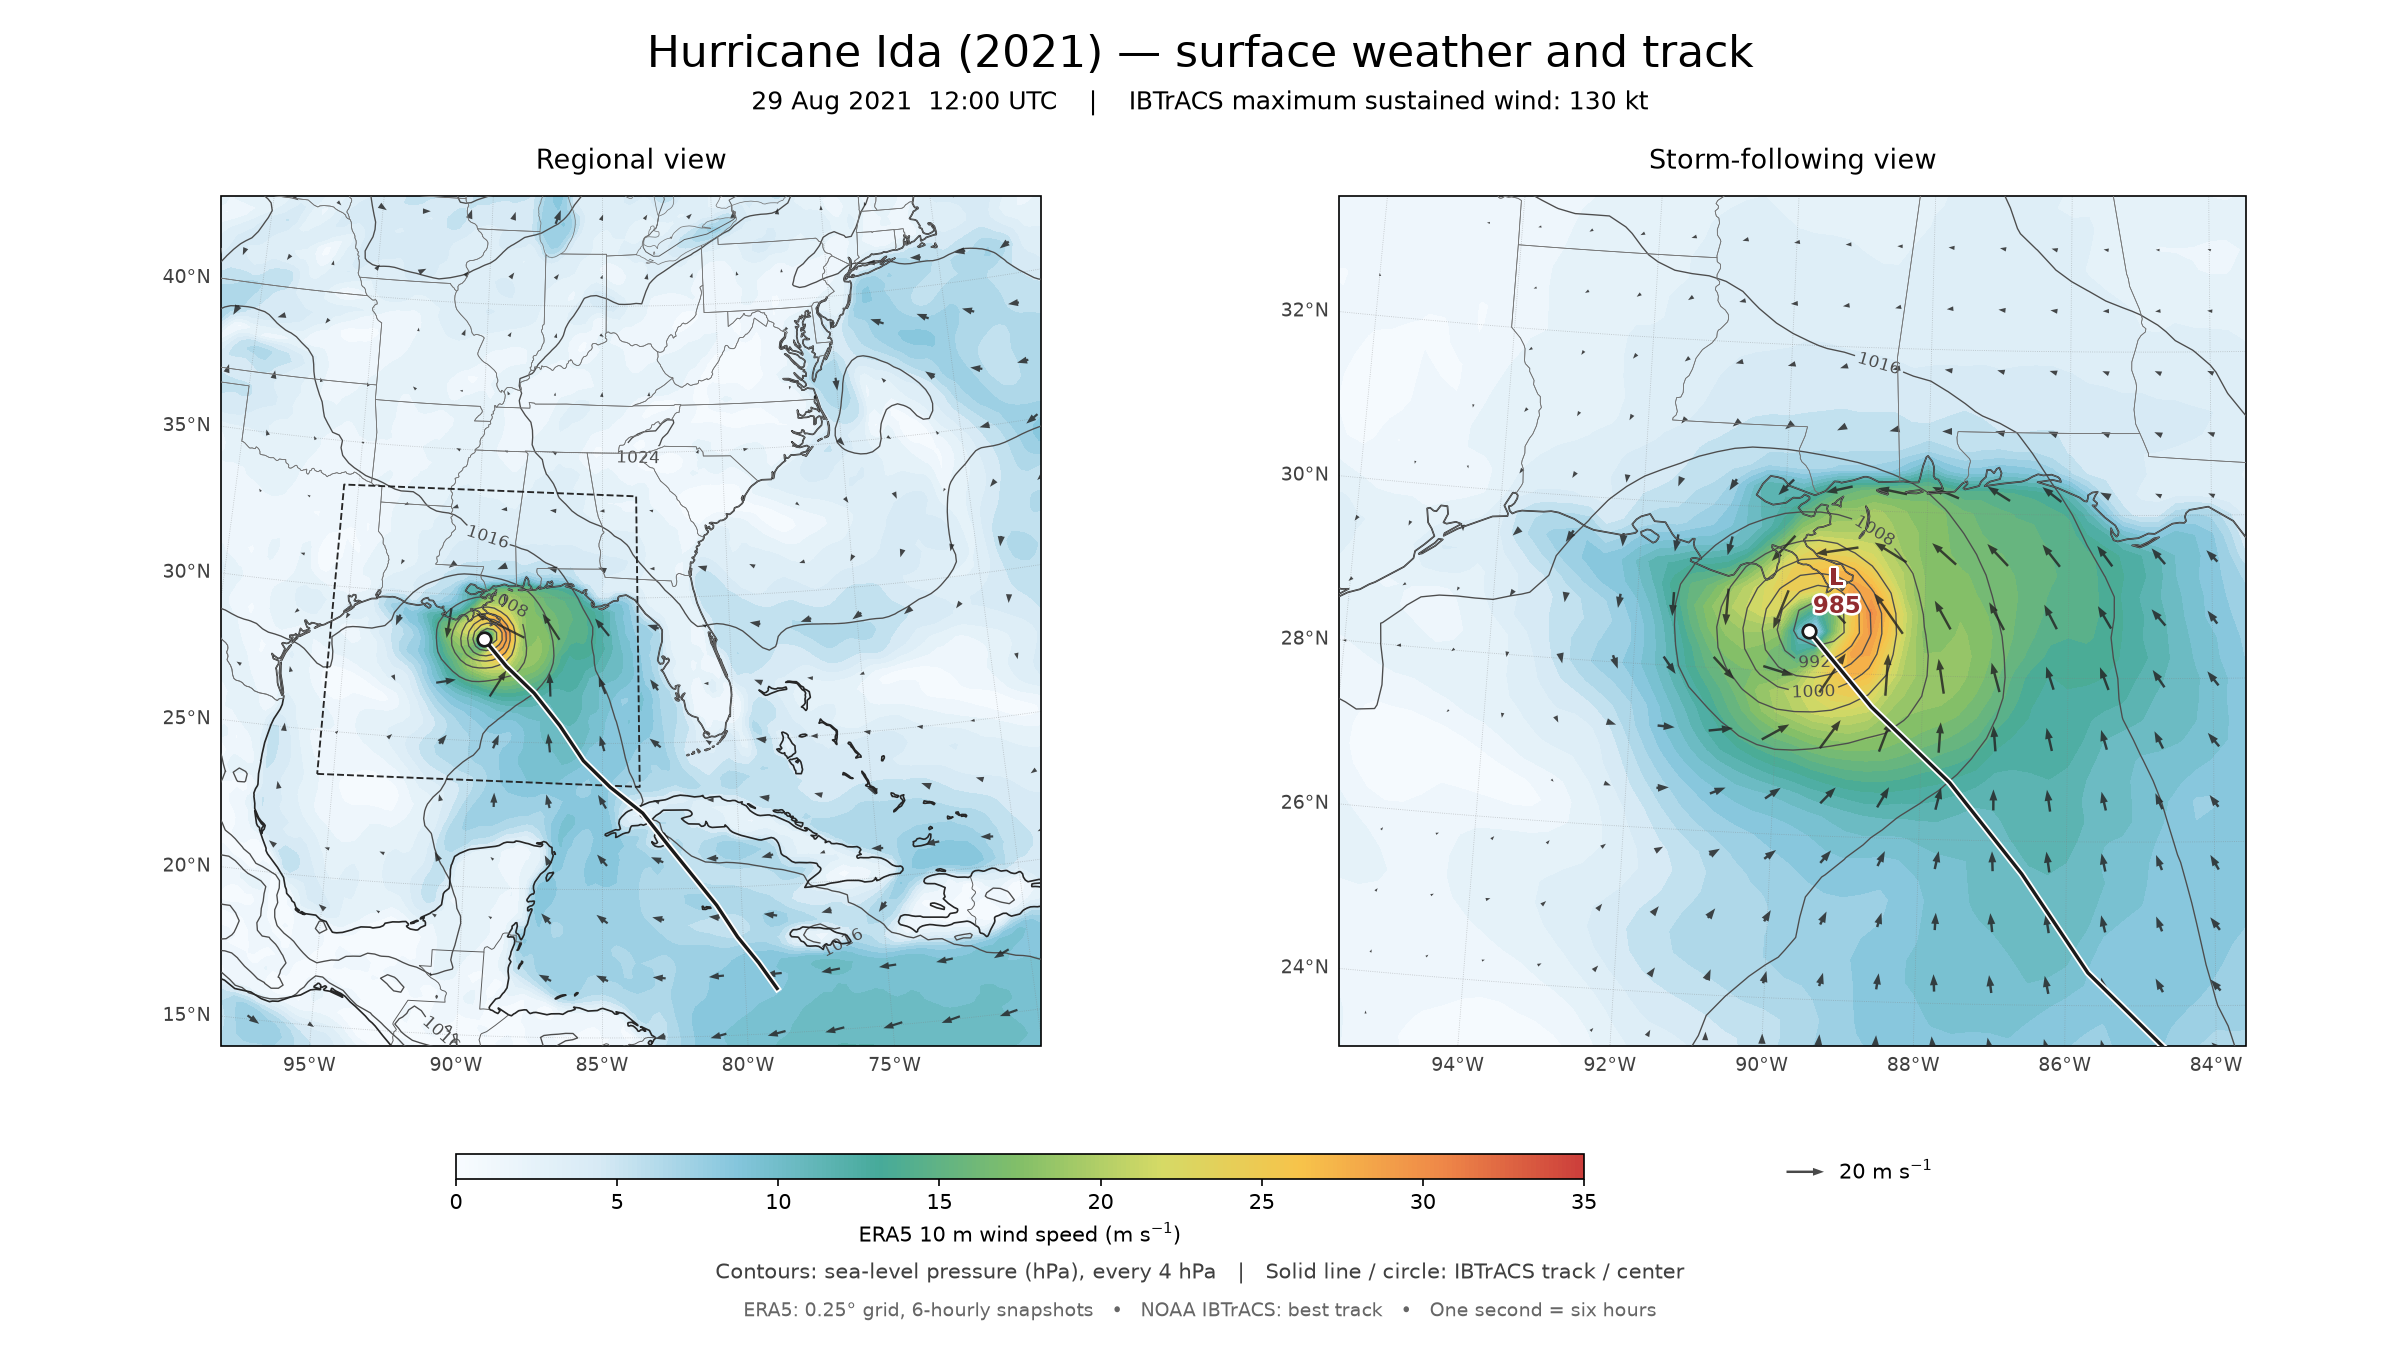

In [17]:
from ida_weather_movie import load_weather, make_figure, draw_frame, save_movie

weather = load_weather(ida)
# In load_weather: speed = sqrt(u10**2 + v10**2), in m/s.
# Sea-level pressure is converted from Pa to hPa by dividing by 100.
# ERA5 timestamps must match the IBTrACS timestamps exactly.
print("ERA5 snapshots:", weather.sizes["valid_time"])

# Check the map near Ida's peak best-track intensity.
peak_frame = int(ida["wind_kt"].idxmax())
preview_fig, maps, time_label = make_figure()
draw_frame(peak_frame, preview_fig, maps, time_label, ida, weather)
preview_fig.savefig("Ida_weather_preview.png", dpi=150, facecolor="white")
plt.close(preview_fig)
from IPython.display import Image, display
display(Image(filename="Ida_weather_preview.png"))

In [18]:
from matplotlib.animation import FuncAnimation

movie_fig, maps, time_label = make_figure()
ani = FuncAnimation(
    movie_fig,
    draw_frame,
    frames=len(ida),
    fargs=(movie_fig, maps, time_label, ida, weather),
    interval=1000,    # Hold each six-hourly weather snapshot for one second.
    blit=False,
    repeat=True,
    cache_frame_data=False,
)
plt.close(movie_fig)


In [19]:
from IPython.display import Video, display

# Export a presentation-ready MP4 and a GIF using the local FFmpeg installation.
gif_path, mp4_path = save_movie(ani)
print("Saved:", mp4_path.name, "and", gif_path.name)
display(Video(str(mp4_path), embed=True, width=1000,
              html_attributes="controls loop playsinline"))


Saved: Ida_weather.mp4 and Ida_weather.gif


I changed my movie so it shows the weather around Ida as well as its path. I used ERA5 surface data and the same 26 six-hourly IBTrACS positions from 26 August to 1 September 2021. I matched the timestamps exactly, so each frame uses a real ERA5 snapshot.

The colors show 10 m wind speed in m/s, the arrows show wind direction and speed, and the contour lines show sea-level pressure in hPa. I used `quiver` for the arrows, which follows Harrison's suggestion. The white circle marks the IBTrACS center, and the line only shows the track up to the current time. The red L labels the lowest ERA5 pressure within two degrees of that center.

The left map stays fixed so it is easy to follow the path. The right map moves with the storm so the circulation is easier to see. Both maps use a Lambert Conformal projection, the same wind color scale, and pressure contours every 4 hPa. I can see the circulation strengthen over the Gulf and then weaken after Ida moves inland. ERA5 has a 0.25-degree grid, so it smooths the storm's strongest winds and small-scale structure. Its gridded wind speed is different from the IBTrACS maximum sustained wind shown at the top.

I used Matplotlib's `FuncAnimation` and saved an MP4 and a GIF. Each weather snapshot stays on screen for one second. The video plays at 24 fps by repeating frames; I did not interpolate the weather between the six-hourly times. The reusable plotting code is in [ida_weather_movie.py](ida_weather_movie.py).


Sources: [ERA5](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels), [NOAA IBTrACS](https://www.ncei.noaa.gov/products/international-best-track-archive), and [Matplotlib quiver](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.quiver.html).
